In [1]:
import sys
print(sys.executable)

c:\Users\Lenovo\projects\uk-power-pipeline\.venv\Scripts\python.exe


In [2]:
import json
import requests

BASE_URL = "https://data.elexon.co.uk/bmrs/api/v1"
date = "2026-10-05"

url = f"{BASE_URL}/balancing/settlement/system-prices/{date}"
response = requests.get(url, params={"format": "json"}, timeout=30)

print("Status code:", response.status_code)
body = response.json()
print("Top level keys:", list(body.keys()))
print("Metadata:", body.get("metadata"))

records = body["data"]
print("Number of records:", len(records))
print("Fields in a record:", list(records[0].keys()))
print()
print("First record:")
print(json.dumps(records[0], indent=2))

Status code: 200
Top level keys: ['metadata', 'data']
Metadata: {'datasets': ['DISEBSP']}
Number of records: 48
Fields in a record: ['settlementDate', 'settlementPeriod', 'startTime', 'createdDateTime', 'systemSellPrice', 'systemBuyPrice', 'bsadDefaulted', 'priceDerivationCode', 'reserveScarcityPrice', 'netImbalanceVolume', 'sellPriceAdjustment', 'buyPriceAdjustment', 'replacementPrice', 'replacementPriceReferenceVolume', 'totalAcceptedOfferVolume', 'totalAcceptedBidVolume', 'totalAdjustmentSellVolume', 'totalAdjustmentBuyVolume', 'totalSystemTaggedAcceptedOfferVolume', 'totalSystemTaggedAcceptedBidVolume', 'totalSystemTaggedAdjustmentSellVolume', 'totalSystemTaggedAdjustmentBuyVolume']

First record:
{
  "settlementDate": "2026-10-05",
  "settlementPeriod": 1,
  "startTime": "2026-10-04T23:00:00Z",
  "createdDateTime": "2026-10-05T23:44:39Z",
  "systemSellPrice": 143.92,
  "systemBuyPrice": 143.92,
  "bsadDefaulted": false,
  "priceDerivationCode": "P",
  "reserveScarcityPrice": 0.0,


In [3]:
from datetime import datetime

for r in records:
    start = datetime.fromisoformat(r["startTime"].replace("Z", "+00:00"))
    created = datetime.fromisoformat(r["createdDateTime"].replace("Z", "+00:00"))
    lag_hours = (created - start).total_seconds() / 3600
    print(f"Period {r['settlementPeriod']:>2} | start {r['startTime']} | created {r['createdDateTime']} | lag {lag_hours:6.1f} h")

Period  1 | start 2026-10-04T23:00:00Z | created 2026-10-05T23:44:39Z | lag   24.7 h
Period  2 | start 2026-10-04T23:30:00Z | created 2026-10-06T00:14:41Z | lag   24.7 h
Period  3 | start 2026-10-05T00:00:00Z | created 2026-10-06T00:44:42Z | lag   24.7 h
Period  4 | start 2026-10-05T00:30:00Z | created 2026-10-06T01:14:36Z | lag   24.7 h
Period  5 | start 2026-10-05T01:00:00Z | created 2026-10-06T01:44:42Z | lag   24.7 h
Period  6 | start 2026-10-05T01:30:00Z | created 2026-10-06T02:16:41Z | lag   24.8 h
Period  7 | start 2026-10-05T02:00:00Z | created 2026-10-06T02:44:44Z | lag   24.7 h
Period  8 | start 2026-10-05T02:30:00Z | created 2026-10-06T03:14:42Z | lag   24.7 h
Period  9 | start 2026-10-05T03:00:00Z | created 2026-10-06T03:44:35Z | lag   24.7 h
Period 10 | start 2026-10-05T03:30:00Z | created 2026-10-06T04:14:37Z | lag   24.7 h
Period 11 | start 2026-10-05T04:00:00Z | created 2026-10-06T04:44:34Z | lag   24.7 h
Period 12 | start 2026-10-05T04:30:00Z | created 2026-10-06T05:14

In [4]:
from pathlib import Path

def fetch_system_prices(date: str) -> dict:
    url = f"{BASE_URL}/balancing/settlement/system-prices/{date}"
    resp = requests.get(url, params={"format": "json"}, timeout=30)
    resp.raise_for_status()
    return resp.json()

date = "2026-10-06"
body = fetch_system_prices(date)
records = body["data"]
print("Records:", len(records))

for r in records:
    start = datetime.fromisoformat(r["startTime"].replace("Z", "+00:00"))
    created = datetime.fromisoformat(r["createdDateTime"].replace("Z", "+00:00"))
    lag_hours = (created - start).total_seconds() / 3600
    print(f"Period {r['settlementPeriod']:>2} | price {r['systemSellPrice']:>8} | created {r['createdDateTime']} | lag {lag_hours:6.1f} h")

# Save the raw response so we can compare it with a later fetch
probe_dir = Path("../data/probe")
probe_dir.mkdir(parents=True, exist_ok=True)
fetched_at = datetime.utcnow().strftime("%Y%m%dT%H%M%SZ")
out_file = probe_dir / f"system_prices_{date}_fetched_{fetched_at}.json"
out_file.write_text(json.dumps(body, indent=2))
print("Saved to", out_file.resolve())

Records: 48
Period  1 | price    139.0 | created 2026-10-06T23:44:36Z | lag   24.7 h
Period  2 | price    141.0 | created 2026-10-07T00:14:39Z | lag   24.7 h
Period  3 | price 141.91425719742062 | created 2026-10-07T00:44:37Z | lag   24.7 h
Period  4 | price    141.0 | created 2026-10-07T01:14:40Z | lag   24.7 h
Period  5 | price    140.0 | created 2026-10-07T01:44:39Z | lag   24.7 h
Period  6 | price   141.96 | created 2026-10-07T02:17:08Z | lag   24.8 h
Period  7 | price   140.23 | created 2026-10-07T02:45:01Z | lag   24.8 h
Period  8 | price    131.1 | created 2026-10-07T03:14:40Z | lag   24.7 h
Period  9 | price    148.5 | created 2026-10-06T03:48:35Z | lag    0.8 h
Period 10 | price    148.5 | created 2026-10-06T04:18:33Z | lag    0.8 h
Period 11 | price   185.12 | created 2026-10-06T04:48:23Z | lag    0.8 h
Period 12 | price   186.86 | created 2026-10-06T05:18:25Z | lag    0.8 h
Period 13 | price    188.5 | created 2026-10-06T05:48:27Z | lag    0.8 h
Period 14 | price   219.06 | 

In [5]:
spec = requests.get("https://data.elexon.co.uk/swagger/v1/swagger.json", timeout=60).json()
print("Total endpoints:", len(spec["paths"]))

keywords = ["fuelhh", "indo", "itsdo", "demand", "wind", "solar", "agws", "dgws"]
for path, ops in spec["paths"].items():
    if any(k in path.lower() for k in keywords):
        op = ops.get("get", {})
        params = [p["name"] for p in op.get("parameters", [])]
        print(f"{path}\n    {op.get('summary')}\n    params: {params}\n")

Total endpoints: 322
/datasets/FUELHH
    Half-hourly generation outturn by fuel type (FUELHH)
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'settlementDateFrom', 'settlementDateTo', 'settlementPeriod', 'fuelType', 'format']

/datasets/FUELHH/stream
    Half-hourly generation outturn by fuel type (FUELHH) stream
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'settlementDateFrom', 'settlementDateTo', 'settlementPeriod', 'fuelType']

/datasets/WINDFOR
    Wind generation forecast (WINDFOR)
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'format']

/datasets/WINDFOR/stream
    Wind generation forecast (WINDFOR) stream
    params: ['publishDateTimeFrom', 'publishDateTimeTo']

/datasets/INDO
    Initial National Demand outturn (INDO)
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'format']

/datasets/INDOD
    Initial National Demand outturn daily (INDOD)
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'format']

/datasets/INDOD/stream
    In

In [6]:
url = f"{BASE_URL}/datasets/FUELHH"
params = {"settlementDateFrom": "2026-10-05", "settlementDateTo": "2026-10-05", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
fuel = body["data"]
print("Number of records:", len(fuel))
print("Fields:", list(fuel[0].keys()))
print()
print("First record:")
print(json.dumps(fuel[0], indent=2))
print()
print("Fuel types:", sorted({r["fuelType"] for r in fuel}))
print("Distinct periods:", len({r["settlementPeriod"] for r in fuel}))

Status: 200
Top level keys: ['data']
Number of records: 960
Fields: ['dataset', 'publishTime', 'startTime', 'settlementDate', 'settlementPeriod', 'fuelType', 'generation']

First record:
{
  "dataset": "FUELHH",
  "publishTime": "2026-10-05T23:00:00Z",
  "startTime": "2026-10-05T22:30:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 48,
  "fuelType": "BIOMASS",
  "generation": 3118
}

Fuel types: ['BIOMASS', 'CCGT', 'COAL', 'INTELEC', 'INTEW', 'INTFR', 'INTGRNL', 'INTIFA2', 'INTIRL', 'INTNED', 'INTNEM', 'INTNSL', 'INTVKL', 'NPSHYD', 'NUCLEAR', 'OCGT', 'OIL', 'OTHER', 'PS', 'WIND']
Distinct periods: 48


In [7]:
url = f"{BASE_URL}/demand/outturn"
params = {"settlementDateFrom": "2026-10-05", "settlementDateTo": "2026-10-05", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
demand = body["data"]
print("Number of records:", len(demand))
print("Fields:", list(demand[0].keys()))
print()
print("First record:")
print(json.dumps(demand[0], indent=2))
print()
print("Distinct periods:", len({r["settlementPeriod"] for r in demand}))

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 48
Fields: ['publishTime', 'startTime', 'settlementDate', 'settlementPeriod', 'initialDemandOutturn', 'initialTransmissionSystemDemandOutturn']

First record:
{
  "publishTime": "2026-10-04T23:30:00Z",
  "startTime": "2026-10-04T23:00:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 1,
  "initialDemandOutturn": 19809,
  "initialTransmissionSystemDemandOutturn": 23607
}

Distinct periods: 48


In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path
import requests

BASE_URL = "https://data.elexon.co.uk/bmrs/api/v1"
date = "2026-10-06"
probe_dir = Path("../data/probe")

# 1. Fetch the same date again and save it with a new timestamp
resp = requests.get(
    f"{BASE_URL}/balancing/settlement/system-prices/{date}",
    params={"format": "json"},
    timeout=30,
)
resp.raise_for_status()
fetched_at = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
new_file = probe_dir / f"system_prices_{date}_fetched_{fetched_at}.json"
new_file.write_text(json.dumps(resp.json(), indent=2))

# 2. Load the earliest and latest saved fetches for this date
files = sorted(probe_dir.glob(f"system_prices_{date}_fetched_*.json"))
print("Saved fetches:", [f.name for f in files])
old = {r["settlementPeriod"]: r for r in json.loads(files[0].read_text())["data"]}
new = {r["settlementPeriod"]: r for r in json.loads(files[-1].read_text())["data"]}

# 3. Compare period by period
changed = []
for p in sorted(new):
    o, n = old[p], new[p]
    version_changed = o["createdDateTime"] != n["createdDateTime"]
    diff = n["systemSellPrice"] - o["systemSellPrice"]
    if version_changed:
        changed.append(abs(diff))
    print(f"Period {p:>2} | old {o['systemSellPrice']:>9.2f} | new {n['systemSellPrice']:>9.2f} "
          f"| diff {diff:>8.2f} | new version: {version_changed}")

print()
print("Periods with a new version:", len(changed))
print("Of those, price actually changed:", sum(1 for d in changed if d > 0.005))
if changed:
    print("Average absolute change (£/MWh):", round(sum(changed) / len(changed), 2))
    print("Largest absolute change (£/MWh):", round(max(changed), 2))

Saved fetches: ['system_prices_2026-10-06_fetched_20261007T031832Z.json', 'system_prices_2026-10-06_fetched_20261007T223608Z.json']
Period  1 | old    139.00 | new    139.00 | diff     0.00 | new version: False
Period  2 | old    141.00 | new    141.00 | diff     0.00 | new version: False
Period  3 | old    141.91 | new    141.91 | diff     0.00 | new version: False
Period  4 | old    141.00 | new    141.00 | diff     0.00 | new version: False
Period  5 | old    140.00 | new    140.00 | diff     0.00 | new version: False
Period  6 | old    141.96 | new    141.96 | diff     0.00 | new version: False
Period  7 | old    140.23 | new    140.23 | diff     0.00 | new version: False
Period  8 | old    131.10 | new    131.10 | diff     0.00 | new version: False
Period  9 | old    148.50 | new    148.50 | diff     0.00 | new version: True
Period 10 | old    148.50 | new    148.50 | diff     0.00 | new version: True
Period 11 | old    185.12 | new    185.12 | diff     0.00 | new version: True
Pe

In [2]:
from collections import Counter

field_changes = Counter()
for p in new:
    if old[p]["createdDateTime"] == new[p]["createdDateTime"]:
        continue
    for field in new[p]:
        if field == "createdDateTime":
            continue
        if old[p].get(field) != new[p].get(field):
            field_changes[field] += 1

if field_changes:
    print("Fields that changed in republished records:")
    for field, count in field_changes.most_common():
        print(f"  {field}: {count} periods")
else:
    print("No fields changed apart from createdDateTime")

No fields changed apart from createdDateTime


In [3]:
url = f"{BASE_URL}/generation/actual/per-type/wind-and-solar"
params = {
    "from": "2026-10-05",
    "to": "2026-10-05",
    "settlementPeriodFrom": 1,
    "settlementPeriodTo": 50,
    "format": "json",
}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
ws = body["data"]
print("Number of records:", len(ws))
print("Fields:", list(ws[0].keys()))
print()
print("First record:")
print(json.dumps(ws[0], indent=2))
print()
for field in ["psrType", "businessType", "settlementDate"]:
    if field in ws[0]:
        print(f"Distinct {field}:", sorted({str(r[field]) for r in ws}))
print("Distinct periods:", len({r["settlementPeriod"] for r in ws}))

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 144
Fields: ['publishTime', 'businessType', 'psrType', 'quantity', 'startTime', 'settlementDate', 'settlementPeriod']

First record:
{
  "publishTime": "2026-10-06T01:00:01Z",
  "businessType": "Wind generation",
  "psrType": "Wind Onshore",
  "quantity": 1810.0,
  "startTime": "2026-10-05T22:30:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 48
}

Distinct psrType: ['Solar', 'Wind Offshore', 'Wind Onshore']
Distinct businessType: ['Solar generation', 'Wind generation']
Distinct settlementDate: ['2026-10-05']
Distinct periods: 48


In [4]:
from datetime import datetime

url = f"{BASE_URL}/forecast/demand/day-ahead/earliest"
params = {"from": "2026-10-05", "to": "2026-10-06", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
fc = body["data"]
print("Number of records:", len(fc))
print("Fields:", list(fc[0].keys()))
print()
print("First record:")
print(json.dumps(fc[0], indent=2))
print()
for field in ["boundary", "settlementDate"]:
    if field in fc[0]:
        print(f"Distinct {field}:", sorted({str(r[field]) for r in fc}))

def to_dt(s):
    return datetime.fromisoformat(s.replace("Z", "+00:00"))

leads = [(to_dt(r["startTime"]) - to_dt(r["publishTime"])).total_seconds() / 3600 for r in fc]
print(f"Hours between publish and the half hour it forecasts: min {min(leads):.1f}, max {max(leads):.1f}")

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 49
Fields: ['startTime', 'settlementDate', 'settlementPeriod', 'boundary', 'publishTime', 'transmissionSystemDemand', 'nationalDemand']

First record:
{
  "startTime": "2026-10-05T00:00:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 3,
  "boundary": "N",
  "publishTime": "2026-10-03T07:45:00Z",
  "transmissionSystemDemand": 20540,
  "nationalDemand": 20040
}

Distinct boundary: ['N']
Distinct settlementDate: ['2026-10-05', '2026-10-06']
Hours between publish and the half hour it forecasts: min 20.2, max 43.8


In [5]:
for r in fc:
    lead = (to_dt(r["startTime"]) - to_dt(r["publishTime"])).total_seconds() / 3600
    print(f"{r['startTime']} | period {r['settlementPeriod']:>2} | published {r['publishTime']} | lead {lead:5.1f} h")

2026-10-05T00:00:00Z | period  3 | published 2026-10-03T07:45:00Z | lead  40.2 h
2026-10-05T00:30:00Z | period  4 | published 2026-10-03T07:45:00Z | lead  40.8 h
2026-10-05T01:00:00Z | period  5 | published 2026-10-03T07:45:00Z | lead  41.2 h
2026-10-05T01:30:00Z | period  6 | published 2026-10-03T07:45:00Z | lead  41.8 h
2026-10-05T02:00:00Z | period  7 | published 2026-10-03T07:45:00Z | lead  42.2 h
2026-10-05T02:30:00Z | period  8 | published 2026-10-03T07:45:00Z | lead  42.8 h
2026-10-05T03:00:00Z | period  9 | published 2026-10-03T07:45:00Z | lead  43.2 h
2026-10-05T03:30:00Z | period 10 | published 2026-10-03T07:45:00Z | lead  43.8 h
2026-10-05T04:00:00Z | period 11 | published 2026-10-04T07:45:00Z | lead  20.2 h
2026-10-05T04:30:00Z | period 12 | published 2026-10-04T07:45:00Z | lead  20.8 h
2026-10-05T05:00:00Z | period 13 | published 2026-10-04T07:45:00Z | lead  21.2 h
2026-10-05T05:30:00Z | period 14 | published 2026-10-04T07:45:00Z | lead  21.8 h
2026-10-05T06:00:00Z | perio

In [6]:
url = f"{BASE_URL}/forecast/generation/wind/earliest"
params = {"from": "2026-10-05", "to": "2026-10-06", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
wf = body["data"]
print("Number of records:", len(wf))
print("Fields:", list(wf[0].keys()))
print()
print("First record:")
print(json.dumps(wf[0], indent=2))
print()

from collections import Counter
publish_counts = Counter(r["publishTime"] for r in wf)
print("Publish times and how many records each:")
for pt, n in sorted(publish_counts.items()):
    print(f"  {pt}: {n}")

leads = [(to_dt(r["startTime"]) - to_dt(r["publishTime"])).total_seconds() / 3600 for r in wf]
print(f"Lead hours: min {min(leads):.1f}, max {max(leads):.1f}")

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 25
Fields: ['publishTime', 'startTime', 'settlementDate', 'settlementPeriod', 'generation']

First record:
{
  "publishTime": "2026-10-03T03:30:00Z",
  "startTime": "2026-10-05T00:00:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 3,
  "generation": 14309
}

Publish times and how many records each:
  2026-10-03T03:30:00Z: 21
  2026-10-04T03:30:00Z: 4
Lead hours: min 41.5, max 64.5


In [7]:
url = f"{BASE_URL}/forecast/generation/wind/history"
params = {"publishTime": "2026-10-04T03:30:00Z", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
wh = body["data"]
print("Number of records:", len(wh))
print("Fields:", list(wh[0].keys()))
print("Distinct publish times:", sorted({r["publishTime"] for r in wh}))

starts = sorted(r["startTime"] for r in wh)
print("Covers from:", starts[0])
print("Covers to:  ", starts[-1])
print()
print("First record:")
print(json.dumps(wh[0], indent=2))

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 73
Fields: ['publishTime', 'startTime', 'settlementDate', 'settlementPeriod', 'generation']
Distinct publish times: ['2026-10-04T03:30:00Z']
Covers from: 2026-10-03T20:00:00Z
Covers to:   2026-10-06T20:00:00Z

First record:
{
  "publishTime": "2026-10-04T03:30:00Z",
  "startTime": "2026-10-03T20:00:00Z",
  "settlementDate": "2026-10-03",
  "settlementPeriod": 43,
  "generation": 5150
}


In [8]:
url = f"{BASE_URL}/forecast/generation/wind/evolution"
params = {"startTime": "2026-10-05T18:00:00Z", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
ev = body["data"]
print("Number of issues for this hour:", len(ev))
print()
for r in sorted(ev, key=lambda r: r["publishTime"]):
    lead = (to_dt(r["startTime"]) - to_dt(r["publishTime"])).total_seconds() / 3600
    print(f"published {r['publishTime']} | lead {lead:5.1f} h | forecast {r['generation']} MW")

Status: 200
Number of issues for this hour: 24

published 2026-10-03T03:30:00Z | lead  62.5 h | forecast 11503 MW
published 2026-10-03T05:30:00Z | lead  60.5 h | forecast 11151 MW
published 2026-10-03T08:30:00Z | lead  57.5 h | forecast 10825 MW
published 2026-10-03T10:30:00Z | lead  55.5 h | forecast 10422 MW
published 2026-10-03T12:30:00Z | lead  53.5 h | forecast 10387 MW
published 2026-10-03T16:30:00Z | lead  49.5 h | forecast 10580 MW
published 2026-10-03T19:30:00Z | lead  46.5 h | forecast 10446 MW
published 2026-10-03T23:30:00Z | lead  42.5 h | forecast 10584 MW
published 2026-10-04T03:30:00Z | lead  38.5 h | forecast 10696 MW
published 2026-10-04T05:30:00Z | lead  36.5 h | forecast 10702 MW
published 2026-10-04T08:30:00Z | lead  33.5 h | forecast 10547 MW
published 2026-10-04T10:30:00Z | lead  31.5 h | forecast 11084 MW
published 2026-10-04T12:30:00Z | lead  29.5 h | forecast 11091 MW
published 2026-10-04T16:30:00Z | lead  25.5 h | forecast 11158 MW
published 2026-10-04T19:30:0

In [9]:
url = f"{BASE_URL}/forecast/generation/wind/history"
for pt in ["2026-10-04T08:30:00Z", "2026-10-04T09:00:00Z"]:
    resp = requests.get(url, params={"publishTime": pt, "format": "json"}, timeout=30)
    data = resp.json().get("data", []) if resp.status_code == 200 else []
    issues = sorted({r["publishTime"] for r in data})
    print(f"Asked for {pt} -> status {resp.status_code}, records {len(data)}, issue(s) returned {issues}")

Asked for 2026-10-04T08:30:00Z -> status 200, records 73, issue(s) returned ['2026-10-04T08:30:00Z']
Asked for 2026-10-04T09:00:00Z -> status 200, records 73, issue(s) returned ['2026-10-04T08:30:00Z']


In [10]:
url = f"{BASE_URL}/forecast/generation/wind-and-solar/day-ahead"
params = {
    "from": "2026-10-05",
    "to": "2026-10-05",
    "settlementPeriodFrom": 1,
    "settlementPeriodTo": 50,
    "format": "json",
}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
dg = body["data"]
print("Number of records:", len(dg))
print("Fields:", list(dg[0].keys()))
print()
print("First record:")
print(json.dumps(dg[0], indent=2))
print()
for field in ["processType", "psrType", "businessType", "settlementDate"]:
    if field in dg[0]:
        print(f"Distinct {field}:", sorted({str(r[field]) for r in dg}))

publish_counts = Counter(r["publishTime"] for r in dg)
print()
print("Publish times and how many records each:")
for pt, n in sorted(publish_counts.items()):
    print(f"  {pt}: {n}")

Status: 400
Top level keys: ['type', 'title', 'status', 'errors', 'traceId']


KeyError: 'data'

In [11]:
print("Status:", resp.status_code)
print(json.dumps(resp.json(), indent=2)[:2000])

Status: 400
{
  "type": "https://tools.ietf.org/html/rfc9110#section-15.5.1",
  "title": "One or more validation errors occurred.",
  "status": 400,
  "errors": {
    "": [
      "Errors found when checking allowed strings"
    ],
    "ProcessType": [
      "A value for the 'ProcessType' parameter or property was not provided.",
      " is not valid for field ProcessType. Allowed values include: all, day ahead, intraday process, intraday total."
    ]
  },
  "traceId": "00-d36ffa62fbd1a955131eec05eea61a48-376169a230c20c1a-00"
}


In [12]:
params["processType"] = "all"
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)
resp.raise_for_status()

dg = resp.json()["data"]
print("Number of records:", len(dg))
print("Fields:", list(dg[0].keys()))
print()
print("First record:")
print(json.dumps(dg[0], indent=2))
print()
for field in ["processType", "psrType", "businessType", "settlementDate"]:
    if field in dg[0]:
        print(f"Distinct {field}:", sorted({str(r[field]) for r in dg}))

print()
print("Records per processType and publish time:")
counts = Counter((r.get("processType"), r["publishTime"]) for r in dg)
for (ptype, pt), n in sorted(counts.items(), key=lambda x: x[0][1]):
    print(f"  {ptype:<18} | {pt} | {n}")

Status: 200
Number of records: 324
Fields: ['publishTime', 'processType', 'businessType', 'psrType', 'startTime', 'settlementDate', 'settlementPeriod', 'quantity']

First record:
{
  "publishTime": "2026-10-04T16:45:03Z",
  "processType": "Day ahead",
  "businessType": "Solar generation",
  "psrType": "Solar",
  "startTime": "2026-10-05T22:30:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 48,
  "quantity": 0.0
}

Distinct processType: ['Day ahead', 'Intraday process', 'Intraday total']
Distinct psrType: ['Solar', 'Wind Offshore', 'Wind Onshore']
Distinct businessType: ['Solar generation', 'Wind generation']
Distinct settlementDate: ['2026-10-05']

Records per processType and publish time:
  Day ahead          | 2026-10-03T16:45:02Z | 6
  Intraday process   | 2026-10-04T07:00:04Z | 6
  Intraday total     | 2026-10-04T11:00:09Z | 6
  Day ahead          | 2026-10-04T16:45:03Z | 138
  Intraday process   | 2026-10-05T07:00:14Z | 96
  Intraday total     | 2026-10-05T11:00:06Z 

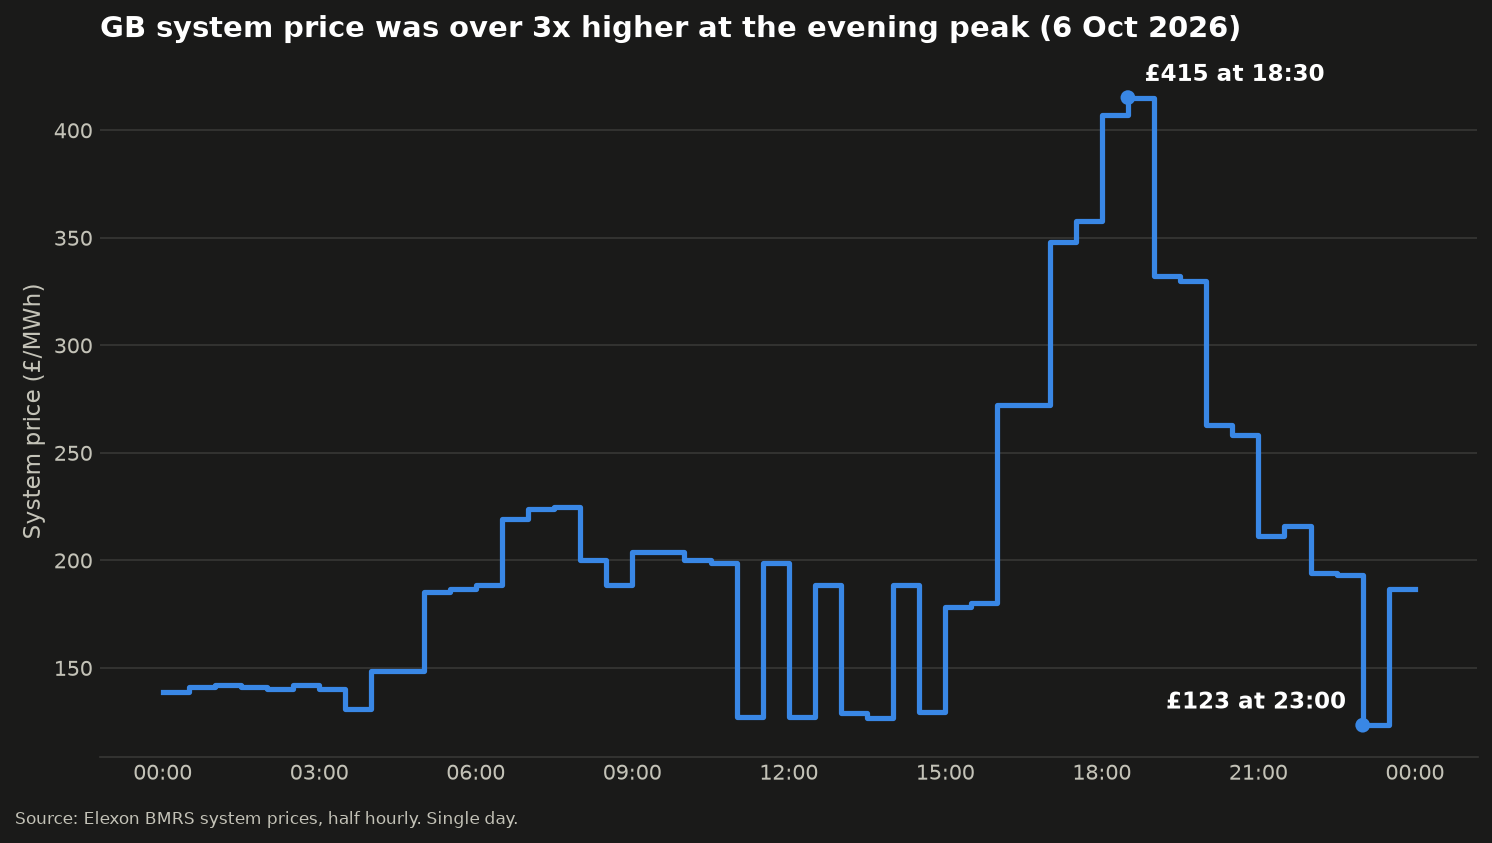

In [16]:
import json
from datetime import datetime, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# Load the latest saved fetch for 6 October
files = sorted(Path("../data/probe").glob("system_prices_2026-10-06_fetched_*.json"))
records = sorted(json.loads(files[-1].read_text())["data"], key=lambda r: r["startTime"])

# Convert start times to UK local time
uk = ZoneInfo("Europe/London")
times = [datetime.fromisoformat(r["startTime"].replace("Z", "+00:00")).astimezone(uk) for r in records]
prices = [r["systemSellPrice"] for r in records]

# Find the real high and low before adding the end point
hi = prices.index(max(prices))
lo = prices.index(min(prices))

# Add an end point at midnight so the last half hour (23:30 to 00:00) is drawn
times.append(times[-1] + timedelta(minutes=30))
prices.append(prices[-1])

# Dark theme colours
surface = "#1a1a19"
line_colour = "#3987e5"
text_primary = "#ffffff"
text_secondary = "#c3c2b7"
grid_colour = "#383835"

fig, ax = plt.subplots(figsize=(10, 5.6), dpi=150)
fig.patch.set_facecolor(surface)
ax.set_facecolor(surface)

# Step line: each price holds for its full half hour
ax.step(times, prices, where="post", color=line_colour, linewidth=2.5)

# Mark and label only the high and the low
labels = [
    (hi, f"£{prices[hi]:.0f} at {times[hi]:%H:%M}", (8, 8), "left"),
    (lo, f"£{prices[lo]:.0f} at {times[lo]:%H:%M}", (-8, 8), "right"),
]
for i, text, offset, align in labels:
    ax.scatter(times[i], prices[i], s=50, color=line_colour, edgecolor="none", zorder=3)
    ax.annotate(text, (times[i], prices[i]), xytext=offset, textcoords="offset points",
                ha=align, fontsize=11, color=text_primary, fontweight="bold")

# Titles and axes
ax.set_title("GB system price was over 3x higher at the evening peak (6 Oct 2026)",
             loc="left", fontsize=14, color=text_primary, pad=14, fontweight="bold")
ax.set_ylabel("System price (£/MWh)", color=text_secondary, fontsize=11)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=uk))

# Quiet grid and axes so the line stands out
ax.grid(axis="y", color=grid_colour, linewidth=0.8)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(grid_colour)
ax.tick_params(colors=text_secondary, length=0, labelsize=10)

fig.text(0.01, 0.01, "Source: Elexon BMRS system prices, half hourly. Single day.",
         fontsize=8, color=text_secondary)

fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("../data/linkedin_part1_prices_dark.png", facecolor=surface)
plt.show()

In [17]:
OM_URL = "https://single-runs-api.open-meteo.com/v1/forecast"

for run in ["2026-10-04T00:00", "2024-10-01T00:00"]:
    params = {
        "latitude": 51.5,
        "longitude": -0.13,
        "run": run,
        "models": "ecmwf_ifs",
        "hourly": "temperature_2m,shortwave_radiation,wind_speed_100m,cloud_cover",
        "timezone": "GMT",
    }
    resp = requests.get(OM_URL, params=params, timeout=60)
    print(f"Run {run} -> status {resp.status_code}")
    if resp.status_code != 200:
        print(resp.text[:500])
        continue

    body = resp.json()
    hourly = body["hourly"]
    times = hourly["time"]
    print("  Top level keys:", list(body.keys()))
    print("  Variables:", [k for k in hourly.keys() if k != "time"])
    print("  Units:", body.get("hourly_units"))
    print(f"  Hours returned: {len(times)}, from {times[0]} to {times[-1]}")
    for i in [0, 12, 36]:
        print(f"  {times[i]} | temp {hourly['temperature_2m'][i]} | solar {hourly['shortwave_radiation'][i]} "
              f"| wind100m {hourly['wind_speed_100m'][i]} | cloud {hourly['cloud_cover'][i]}")
    print()

Run 2026-10-04T00:00 -> status 200
  Top level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
  Variables: ['temperature_2m', 'shortwave_radiation', 'wind_speed_100m', 'cloud_cover']
  Units: {'time': 'iso8601', 'temperature_2m': '°C', 'shortwave_radiation': 'W/m²', 'wind_speed_100m': 'km/h', 'cloud_cover': '%'}
  Hours returned: 168, from 2026-10-04T00:00 to 2026-10-10T23:00
  2026-10-04T00:00 | temp 13.8 | solar None | wind100m 1.8 | cloud 23
  2026-10-04T12:00 | temp 19.3 | solar 508.0 | wind100m 9.3 | cloud 65
  2026-10-05T12:00 | temp 20.0 | solar 455.0 | wind100m 14.2 | cloud 35

Run 2024-10-01T00:00 -> status 200
  Top level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
  Variables: ['temperature_2m', 'shortwave_radiation', 'wind_speed_100m', 'cloud_cover']
  Units: {'time'

In [18]:
locations = {
    "wind_off_hornsea": (53.9, 1.8),
    "wind_off_dogger": (54.8, 1.9),
    "solar_cambs": (52.3, 0.1),
    "temp_london": (51.5, -0.13),
}

params = {
    "latitude": ",".join(str(lat) for lat, _ in locations.values()),
    "longitude": ",".join(str(lon) for _, lon in locations.values()),
    "run": "2026-10-04T00:00",
    "models": "ecmwf_ifs",
    "hourly": "temperature_2m,shortwave_radiation,wind_speed_100m,cloud_cover",
    "timezone": "GMT",
}
resp = requests.get(OM_URL, params=params, timeout=60)
print("Status:", resp.status_code)
body = resp.json()
print("Response type:", type(body).__name__)

if isinstance(body, list):
    print("Number of locations returned:", len(body))
    for name, loc in zip(locations, body):
        h = loc["hourly"]
        print(f"  {name:<18} | lat {loc['latitude']:.2f} lon {loc['longitude']:.2f} "
              f"| hours {len(h['time'])} | wind100m at 12:00 {h['wind_speed_100m'][12]}")
else:
    print(json.dumps(body, indent=2)[:800])

Status: 200
Response type: list
Number of locations returned: 4
  wind_off_hornsea   | lat 53.88 lon 1.74 | hours 168 | wind100m at 12:00 28.3
  wind_off_dogger    | lat 54.80 lon 1.96 | hours 168 | wind100m at 12:00 36.5
  solar_cambs        | lat 52.27 lon 0.17 | hours 168 | wind100m at 12:00 11.6
  temp_london        | lat 51.49 lon -0.16 | hours 168 | wind100m at 12:00 9.3


In [19]:
CI_URL = "https://api.carbonintensity.org.uk"

resp = requests.get(f"{CI_URL}/intensity/2026-10-05T00:00Z/2026-10-06T00:00Z",
                    headers={"Accept": "application/json"}, timeout=30)
print("Status:", resp.status_code)
body = resp.json()
print("Top level keys:", list(body.keys()))

ci = body["data"]
print("Number of records:", len(ci))
print()
print("First record:")
print(json.dumps(ci[0], indent=2))
print()
print("Last record:")
print(json.dumps(ci[-1], indent=2))

missing_actual = sum(1 for r in ci if r["intensity"].get("actual") is None)
print()
print("Records with no actual value:", missing_actual)

Status: 200
Top level keys: ['data']
Number of records: 49

First record:
{
  "from": "2026-10-04T23:30Z",
  "to": "2026-10-05T00:00Z",
  "intensity": {
    "forecast": 105,
    "actual": 97,
    "index": "moderate"
  }
}

Last record:
{
  "from": "2026-10-05T23:30Z",
  "to": "2026-10-06T00:00Z",
  "intensity": {
    "forecast": 185,
    "actual": 184,
    "index": "high"
  }
}

Records with no actual value: 0
